# 01 · 前向扩散：一张图怎样变成雪花？

拿一张颜色清楚的棋盘图，逐渐压低原图的“音量”，同时调高随机噪声的“音量”。格子慢慢被雪花盖住，最后越来越难认出来。

这一篇亲手做这个过程：安排每一步的噪声，推导直接跳到某个时刻的公式，再把图像变化画出来。它是扩散模型中**前向加噪**这一半，后面学习去噪时会反复用到。

## 准备画布

在 `diffusion-model` 目录运行 `uv sync --python 3.11.15`、`uv run jupyter lab`，或在 VS Code 选择 `diffusion-model/.venv/bin/python`。图片由代码生成，运行结果直接显示在 Notebook 中。

从第一格开始，先固定随机种子，方便反复观察同一组噪声。环境详情见[仓库入口](../README.md)。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

torch.manual_seed(42)
np.random.seed(42)

## 先看一次加噪到底做了什么

把一滴墨水放进清水，原来集中的结构会逐渐散开。图像扩散也借用了这种“结构逐渐消失”的直觉，具体计算是给像素加入随机的高斯噪声：

$$x_t=\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,\epsilon_t,
\qquad \epsilon_t\sim\mathcal N(0,I).$$

读成一句话：**上一幅图缩小一点，再加一份随机雪花。** β_t 决定这一轮的噪声方差，噪声本身则每次抽样产生。

先记住三个角色：x₀ 是干净图，xₜ 是第 t 次加噪后的图，εₜ 是这一轮新抽出的噪声。等它们走上几步，再来合并公式。

### 两个“音量旋钮”怎样变化？

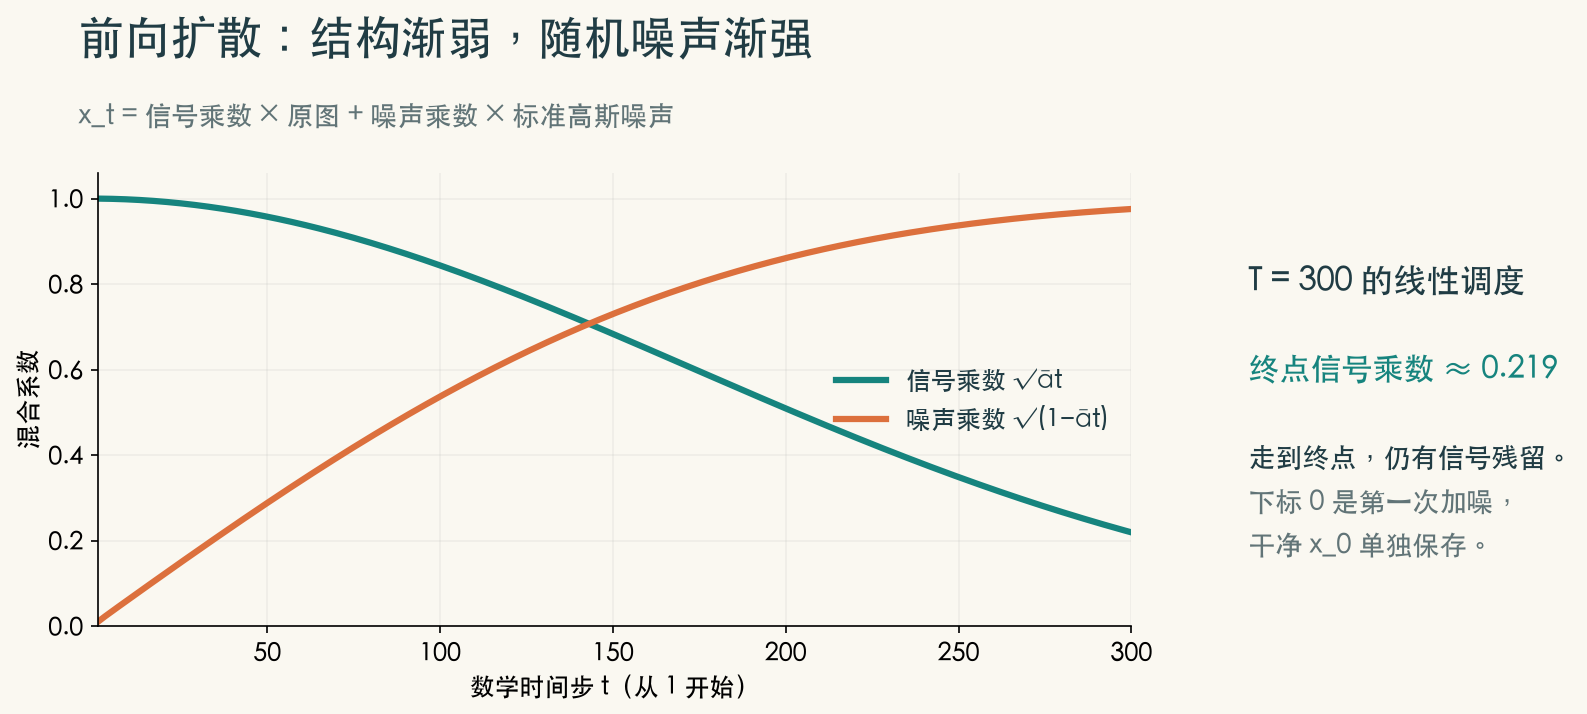

绿色是原图的乘数，橙色是噪声的乘数。一边渐弱，一边渐强；它们的平方相加为 1。下面先把这两条曲线算出来。

## 1. 每次削弱一点，累计会怎样？

我们用 β 记录本步加入多少噪声，用 $\alpha_t=1-\beta_t$ 记录本步信号乘数的平方。走过多步后，原图会被这些缩放系数连续相乘：

$$\bar\alpha_t=\alpha_1\alpha_2\cdots\alpha_t.$$

上面多出来的一横，就提醒我们：**这是一路累计到第 t 步的量。** 原图最终的乘数是 $\sqrt{\bar\alpha_t}$。

| 代码 | 读法 |
| --- | --- |
| `betas` | 每一步的噪声方差 |
| `alphas = 1 - betas` | 每一步信号乘数的平方 |
| `cumprod(alphas)` | 把这些数从头累乘，得到每个时刻的累计值 |

数组从 0 开始，所以 `betas[0]` 对应数学上的第 1 次加噪；干净图单独记作 x₀。

In [ ]:
T = 300
beta_start, beta_end = 1e-4, 0.02
betas = torch.linspace(beta_start, beta_end, T)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

steps = torch.arange(1, T + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(steps.numpy(), betas.numpy())
axes[0].set_title("Per-step noise variance")
axes[1].plot(steps.numpy(), alphas_cumprod.numpy())
axes[1].set_title("Cumulative signal coefficient squared")
for ax in axes:
    ax.set_xlabel("Diffusion step (1-based)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Terminal alpha_bar:", alphas_cumprod[-1].item())
print("Terminal signal multiplier:", sqrt_alphas_cumprod[-1].item())

看右边的累计曲线：即使每一步只削弱一点，连乘很多次后，信号也会明显变小。它记录了原图一路被调低音量的过程。

## 2. 能直接跳到第 200 步吗？

可以。独立高斯噪声的线性组合仍是高斯，我们可以把前面各步的噪声合成一份，一次算出指定时刻的图：

$$x_t=\sqrt{\bar\alpha_t}\,x_0+
\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad\epsilon\sim\mathcal N(0,I).$$

现在公式里只有两项：**原图 × 信号乘数 + 噪声 × 噪声乘数**。训练去噪网络时，随机挑一个 t，就能用它快速准备相应的带噪输入。

<details>
<summary>展开前两步，看看噪声为什么能合并</summary>

把第一步代进第二步：

$$x_2=\sqrt{\alpha_1\alpha_2}x_0+
\sqrt{\alpha_2(1-\alpha_1)}\epsilon_1+
\sqrt{1-\alpha_2}\epsilon_2.$$

后两项独立，方差相加得到：

$$\alpha_2(1-\alpha_1)+(1-\alpha_2)=1-\alpha_1\alpha_2.$$

于是它们可以写成 $\sqrt{1-\bar\alpha_2}\epsilon$，其中 ε 是一份新的标准高斯噪声。按同样方式继续展开，就得到任意 t 的直接采样公式。

</details>

下面的 `q_sample` 接收 `(B,C,H,W)` 图像和 `(B,)` 时间索引。每张图取到自己的系数，再把系数排成 `(B,1,1,1)`，共享给该图的所有像素。

In [ ]:
def q_sample(x_0: torch.Tensor, t: torch.Tensor, noise: torch.Tensor = None):
    """
    从 x_0 一步直接计算 x_t（不需要逐步迭代！）

    参数:
        x_0:   干净图像 [B, C, H, W], 取值范围 [-1, 1]
        t:     时间步 [B], 取值 0 ~ T-1
        noise: 可选, 预先采样的噪声 ε ~ N(0, I)
    返回:
        x_t:   加噪后的图像 [B, C, H, W]
    """
    if noise is None:
        noise = torch.randn_like(x_0)  # ε ~ N(0, I)

    # 提取 t 对应的系数, reshape 为 [B, 1, 1, 1] 以便 broadcasting
    sqrt_a = sqrt_alphas_cumprod[t].view(-1, 1, 1, 1)       # √ᾱ_t
    sqrt_1ma = sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1)  # √(1-ᾱ_t)

    # ★ 核心公式 ★
    # x_t = √ᾱ_t · x_0 + √(1-ᾱ_t) · ε
    x_t = sqrt_a * x_0 + sqrt_1ma * noise
    return x_t

读 `q_sample` 的最后一行，就能和公式一项项对上：`sqrt_a * x_0` 留下原图内容，`sqrt_1ma * noise` 加入相应强度的雪花。

## 3. 画一张容易看出变化的图

用渐变颜色当背景，再叠一层棋盘格。渐变展示大范围的结构，格子展示局部细节，二者都方便在加噪后寻找踪迹。

计算时将像素放到 `[-1,1]`；显示时再映射回 `[0,1]`。下一格先画出干净的 x₀。

In [ ]:
def create_example_image(size=64):
    """
    生成一张彩色棋盘格+渐变色的合成图, 用来直观展示加噪效果
    返回: [1, 3, size, size], 范围 [-1, 1]
    """
    img = np.zeros((size, size, 3), dtype=np.float32)

    # 创建一个有丰富颜色的图案
    for i in range(size):
        for j in range(size):
            # 渐变红色通道
            img[i, j, 0] = i / size
            # 渐变绿色通道 (对角)
            img[i, j, 1] = (i + j) / (2 * size)
            # 棋盘蓝色通道
            img[i, j, 2] = 1.0 if (i // 8 + j // 8) % 2 == 0 else 0.3

    # [0, 1] → [-1, 1]
    img = img * 2.0 - 1.0

    # [H, W, C] → [1, C, H, W]  (PyTorch 标准 BCHW 格式)
    tensor = torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0)
    return tensor

def tensor_to_display(x: torch.Tensor):
    """[-1,1] tensor → [0,1] numpy for matplotlib"""
    x = x.clamp(-1, 1)
    x = (x + 1.0) / 2.0
    return x.squeeze(0).permute(1, 2, 0).numpy()

x_0 = create_example_image(size=64)
print("Image shape:", x_0.shape)
plt.figure(figsize=(4, 4))
plt.imshow(tensor_to_display(x_0))
plt.title("Clean x_0")
plt.axis("off")
plt.show()

PyTorch 把图像排成 BCHW：批次、通道、高、宽；绘图函数需要 HWC：高、宽、通道。`permute` 负责换这个摆放顺序。

`tensor_to_display` 还会把超出显示范围的值截到边界，这一步只用在画图时。

## 4. 固定一份雪花，只调两个旋钮

先抽一份 noise，在不同时间步重复使用它。这样雪花的位置保持相同，我们更容易看出：随着系数变化，原图怎样被逐渐盖住。

下一格从第 1 步到第 T 步选出几个时刻，把它们和干净图放在同一排。

<details>
<summary>这排图怎样对应逐步加噪？</summary>

每张图都按对应时刻的 `q(x_t | x_0)` 直接采样，并共享同一份 ε 来比较系数。如果要模拟一条逐步的马尔可夫轨迹，则每一步使用上一幅图，再抽一份独立噪声。

</details>

In [ ]:
noise = torch.randn_like(x_0)
selected_steps = np.unique(np.linspace(1, T, 7, dtype=int))
fig, axes = plt.subplots(1, len(selected_steps) + 1, figsize=(16, 3))
axes[0].imshow(tensor_to_display(x_0))
axes[0].set_title("Clean x_0")
for ax, step in zip(axes[1:], selected_steps):
    index = int(step) - 1
    x_t = q_sample(x_0, torch.tensor([index]), noise=noise)
    ax.imshow(tensor_to_display(x_t))
    ax.set_title(f"Step {step}\nalpha_bar={alphas_cumprod[index]:.3f}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

从左往右找棋盘格：在哪一幅开始难以辨认？再找大范围的渐变颜色，看看它是否还能透过雪花显露出来。每幅图标题里的 alpha_bar，记录了这个时刻的累计信号系数平方。

## 5. 把 300 步换成 1000 步，终点会怎样？

沿用相同的 β 起止值，多走一些步，就会多乘许多小于 1 的 α，原图的最终乘数也会更小。

按当前设置，300 步时信号乘数约为 0.22，1000 步时约为 0.006。下面直接打印这两个数，看看原图在终点还留下多少系数。

In [ ]:
for total_steps in [300, 1000]:
    schedule = torch.linspace(beta_start, beta_end, total_steps)
    terminal_alpha = torch.prod(1.0 - schedule)
    print(
        f"T={total_steps}: alpha_bar={terminal_alpha.item():.6f}, "
        f"signal multiplier={terminal_alpha.sqrt().item():.6f}"
    )
terminal_sample = q_sample(x_0, torch.tensor([T - 1]), noise=noise)
print("Current terminal sample mean:", terminal_sample.mean().item())
print("Current terminal sample std:", terminal_sample.std().item())

信号乘数越接近 0，终点里原图的贡献越弱，条件分布越接近标准高斯。代码还打印样本的均值和标准差，它们描述这一张采样图的整体数值状态；信号乘数则直接说明原图的保留程度。

## 6. 加噪也可以换一种节奏

刚才让 β 随时间线性增加，相当于按固定步幅调高每一步的噪声方差：

$$\beta_t=\beta_{start}+\frac{t-1}{T-1}(\beta_{end}-\beta_{start}).$$

余弦调度换个思路：先安排“原图的音量怎样渐弱”，再倒推每一步该加多少噪声：

$$\bar\alpha_t=\frac{f(t)}{f(0)},\quad
f(t)=\cos^2\left(\frac{t/T+s}{1+s}\frac\pi2\right).$$

由相邻两步的累计系数，得到 $\beta_t=1-\bar\alpha_t/\bar\alpha_{t-1}$。代码把 β 最大值设为 0.999，让最后一步也保留一个正的 α。

下面把两种曲线画在一起。观察前半程、中段、末段各自怎样分配信号的衰减；这格使用独立变量，前面的图仍采用原来的线性调度。

In [ ]:
cosine_s = 0.008
cosine_time = torch.linspace(0, T, T + 1) / T
cosine_curve = torch.cos((cosine_time + cosine_s) / (1 + cosine_s) * torch.pi / 2).square()
cosine_curve = cosine_curve / cosine_curve[0]
cosine_betas = (1 - cosine_curve[1:] / cosine_curve[:-1]).clamp(1e-8, 0.999)
cosine_alpha_bar = torch.cumprod(1 - cosine_betas, dim=0)
plt.figure(figsize=(8, 3))
plt.plot(steps.numpy(), alphas_cumprod.numpy(), label="Linear beta")
plt.plot(steps.numpy(), cosine_alpha_bar.numpy(), label="Cosine alpha_bar")
plt.xlabel("Step (1-based)")
plt.ylabel("Cumulative signal coefficient squared")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 现在，带噪训练图已经会做了

这篇学会了三件事：安排噪声调度、直接采样任意时刻的图、用累计系数解释图像变化。

<details>
<summary>β、α、alpha_bar 怎样串起来？</summary>

β 是单步噪声方差，α=1−β。把 α 从头累乘得到 alpha_bar，再开平方，就是直接采样时乘在原图前面的系数。

</details>

<details>
<summary>为什么能跳到任意时刻？</summary>

逐步加入的独立高斯噪声可以合并，得到累计方差 1−alpha_bar。因此能从原图直接构造该时刻的条件采样。

</details>

<details>
<summary>去噪网络接下来要学什么？</summary>

一种常用目标是：给网络带噪图 x_t 和时间 t，让它预测加入的噪声 ε。前向采样公式同时提供了输入和目标，这就把加噪过程接到了学习任务上。

</details>

可以先改总步数或 β 的范围，再猜一猜新曲线和终点图会怎么变。下一课将沿着这些带噪样本，进入逆向去噪与生成。